# RQ4 Attacker-based re-identification risk

## 1. Setup

In [1]:
from pathlib import Path
from types import SimpleNamespace
from collections import defaultdict
import json, os, re, sys, unicodedata, importlib, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 140)

plt.rcParams.update({
    "figure.dpi": 170,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def repo():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "document_generator").exists() and (q / "thesis_project").exists():
            return q
        if (q / "UI").exists() and (q / "notebooks").exists():
            return q
    return p

def norm(x):
    s = unicodedata.normalize("NFKD", str(x or ""))
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", s.strip().lower())

def key(x):
    return re.sub(r"[^a-z0-9]+", "", norm(x))

def vals(x):
    return [v.strip() for v in str(x or "").split("|") if v.strip() and v.strip().lower() not in {"nan", "ng"}]

def rate(a, b):
    return float(a) / float(b) if b else 0.0

root = repo()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from thesis_project.dataset import DatasetManager
from thesis_project.experiments import Experiments
from thesis_project.shared import Config, canon, _norm
from thesis_project.attacker import Attacker, knowledge_levels, direct_labels

work = root / "notebooks" / "workspace"
img = root / "images"
out = work / "rq4_attacker_outputs"
img.mkdir(parents=True, exist_ok=True)
out.mkdir(parents=True, exist_ok=True)

sid = "b10a2abb3ea1"
qlabs = {"Programme", "Course code", "Group label", "Role", "Date"}
dlabs = {canon(x) for x in direct_labels}
phases = ["original", "direct_removed", "after_defender", "full_removal"]
phase_name = {
    "original": "Original",
    "direct_removed": "Direct removed",
    "after_defender": "After defender",
    "full_removal": "Full removal",
}

## 2. Shared attacker functions

The notebook uses the existing attacker implementation. Hash filtering calls `hash_filter_attack`. Ranking calls `generate_candidates`, `score_candidates`, `rank_candidates`, `predict_closed_world`, and `predict_open_world`.

In [2]:
def ent(e):
    return {
        "label": canon(e.get("label", "")),
        "surface": str(e.get("surface", "") or ""),
        "region": str(e.get("region", "") or ""),
        "path": str(e.get("path", "") or ""),
        "start": int(e.get("start", -1) or -1),
        "end": int(e.get("end", -1) or -1),
    }

def uniq(xs):
    seen = set()
    out = []
    for x in xs:
        k = _norm(x)
        if k and k not in seen:
            seen.add(k)
            out.append(k)
    return tuple(sorted(out))

def sig(did, ents):
    labs = defaultdict(list)
    for e in ents:
        labs[canon(e.get("label", ""))].append(e.get("surface", ""))
    return {
        "doc_id": did,
        "full_names": uniq([*labs.get("Name", []), *labs.get("FULL_NAME", [])]),
        "student_numbers": uniq(labs.get("Student number", [])),
        "emails": uniq(labs.get("Institutional email", [])),
        "course_codes": uniq(labs.get("Course code", [])),
        "group_labels": uniq(labs.get("Group label", [])),
        "programmes": uniq(labs.get("Programme", [])),
        "roles": uniq(labs.get("Role", [])),
        "dates": uniq(labs.get("Date", [])),
        "num_detections": len(ents),
        "detections": ents,
    }

def attack_tables(records, maps, kb, truth, attacker, source):
    rows = []
    for rec in records:
        tids = set(truth.get(rec.doc_id, []))
        if not tids:
            continue
        for ph in phases:
            for level in knowledge_levels:
                rows.append(attacker.hash_filter_attack(
                    rec,
                    maps[ph].get(rec.doc_id, []),
                    kb,
                    tids,
                    phase=ph,
                    knowledge_level=level,
                ))
    h = pd.DataFrame(rows)
    if h.empty:
        return h, h
    h["source"] = source

    rrows = []
    for rec in records:
        tids = set(truth.get(rec.doc_id, []))
        if not tids:
            continue
        for ph in phases:
            s = sig(rec.doc_id, maps[ph].get(rec.doc_id, []))
            cand = attacker.generate_candidates(s, kb)
            scored = attacker.score_candidates(s, cand)
            ranked = attacker.rank_candidates(scored)
            top = attacker.predict_closed_world(ranked)
            pred = attacker.predict_open_world(ranked)
            rank = next((i + 1 for i, x in enumerate(ranked) if x["record"] in tids), None)
            rrows.append({
                "source": source,
                "doc_id": rec.doc_id,
                "phase": ph,
                "signals": sum(len(v) for v in s.values() if isinstance(v, tuple)),
                "candidates": len(cand),
                "true_profiles": len(tids),
                "top1": int(bool(top and top in tids)),
                "top5": int(any(x["record"] in tids for x in ranked[:5])),
                "mrr": 1 / rank if rank else 0.0,
                "open_correct": int(bool(pred and pred in tids)),
                "open_false_accept": int(bool(pred and pred not in tids)),
            })
    r = pd.DataFrame(rrows)
    return h, r

def summarise(h, r):
    hs = h.groupby(["source", "phase", "knowledge_level"], as_index=False).agg(
        documents=("doc_id", "nunique"),
        mean_mentions=("remaining_identifier_mentions", "mean"),
        reidentified_documents=("any_reidentification", "sum"),
        reidentification_rate=("any_reidentification", "mean"),
        mean_revealed_profiles=("revealed_profiles", "mean"),
        direct_hash_profiles=("direct_hash_revealed_profiles", "sum"),
        direct_hash_hits=("direct_hash_candidate_hits", "sum"),
        quasi_unique_success=("quasi_unique_success", "mean"),
        median_quasi_pool=("quasi_candidate_pool_size", "median"),
    )
    rs = r.groupby(["source", "phase"], as_index=False).agg(
        documents=("doc_id", "nunique"),
        mean_signals=("signals", "mean"),
        median_candidates=("candidates", "median"),
        top1=("top1", "mean"),
        top5=("top5", "mean"),
        mrr=("mrr", "mean"),
        open_correct=("open_correct", "mean"),
        open_false_accept=("open_false_accept", "mean"),
    )
    return hs, rs

def savefig(name):
    plt.savefig(img / f"{name}.png", bbox_inches="tight")
    plt.show()

## 3. Synthetic RQ1 and RQ2 documents

This part uses the same generated workspace dataset as RQ1 and RQ2. The knowledge base is the generator-derived master profile file.

In [3]:
data = work / "dataset"
model = work / "tuned_models" / "name_candidate_model.joblib"
assert data.exists(), f"Synthetic workspace dataset not found at {data}"

has_ocr = importlib.util.find_spec("easyocr") is not None
cfg = Config(
    output=work / "rq4_synthetic_attacker",
    patterns=True,
    ner=True,
    ocr=has_ocr,
    link=True,
    strict=True,
    direct=True,
    quasi=True,
    labels=("Course code", "Group label", "Programme", "Date", "Role"),
    regions=(),
    pdf=False,
    candidate=str(model) if model.exists() else None,
    ner_backend="hybrid",
    gliner_model="urchade/gliner_multi-v2.1",
    gliner_threshold=0.35,
    fallback=True,
)

dm = DatasetManager(data)
records = dm.load_manifest()
kb_path = dm.build_master_profiles_reference()
atk = Attacker(cfg)
kb = atk.load_knowledge_base(kb_path)
exp = Experiments(data, cfg)
docs = exp.rq1_documents()

def gold_entities(rec):
    ann = dm.load_annotations(dm.attach(rec))
    es = list(ann.get("text_entities", [])) + list(ann.get("ocr_entities", []))
    return [ent(e) for e in es if str(e.get("surface", "")).strip()]

before = {r.doc_id: gold_entities(r) for r in docs}
rq1 = exp.rq1()
after = {r.doc_id: [] for r in docs}
for row in rq1.get("per_document", []):
    after[row.get("doc_id", "")] = [ent(e) for e in row.get("remaining_entities", []) if str(e.get("surface", "")).strip()]

maps_syn = {
    "original": before,
    "direct_removed": {d: [e for e in es if canon(e["label"]) not in dlabs] for d, es in before.items()},
    "after_defender": after,
    "full_removal": {d: [] for d in before},
}

truth_syn = {}
for did, es in before.items():
    ids = set()
    for e in es:
        if canon(e["label"]) in {"FULL_NAME", "Name", "Student number", "Institutional email"}:
            ids |= set(atk.direct_hash_matches(e, kb))
    truth_syn[did] = sorted(ids)

rec_syn = [r for r in docs if truth_syn.get(r.doc_id)]
h_syn, r_syn = attack_tables(rec_syn, maps_syn, kb, truth_syn, atk, "Synthetic")
hs_syn, rs_syn = summarise(h_syn, r_syn)

scope_syn = pd.DataFrame([{
    "source": "Synthetic",
    "documents": len(rec_syn),
    "profiles": len(kb),
    "original_mentions": sum(len(v) for v in maps_syn["original"].values()),
    "after_defender_mentions": sum(len(v) for v in maps_syn["after_defender"].values()),
    "knowledge_base": str(kb_path.relative_to(root)),
}])

display(scope_syn)
display(hs_syn.round(3))
display(rs_syn.round(3))

Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 29959.31it/s]
Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.
Using CPU. Note: This module is much faster with a GPU.


,source,documents,profiles,original_mentions,after_defender_mentions,knowledge_base
0,Synthetic,84,3500,8768,18,notebooks\workspace\dataset\master_profiles.csv


,source,phase,knowledge_level,documents,mean_mentions,reidentified_documents,reidentification_rate,mean_revealed_profiles,direct_hash_profiles,direct_hash_hits,quasi_unique_success,median_quasi_pool
0,Synthetic,after_defender,medium,84,0.214,1,0.012,0.012,1,1,0.0,3500.0
1,Synthetic,after_defender,strong,84,0.214,1,0.012,0.012,1,1,0.0,3500.0
2,Synthetic,after_defender,weak,84,0.214,1,0.012,0.012,1,1,0.0,3500.0
3,Synthetic,direct_removed,medium,84,5.500,0,0.000,0.000,0,0,0.0,10.0
4,Synthetic,direct_removed,strong,84,5.500,0,0.000,0.000,0,0,0.0,10.0
5,Synthetic,direct_removed,weak,84,5.500,0,0.000,0.000,0,0,0.0,42.0
6,Synthetic,full_removal,medium,84,0.000,0,0.000,0.000,0,0,0.0,3500.0
7,Synthetic,full_removal,strong,84,0.000,0,0.000,0.000,0,0,0.0,3500.0
8,Synthetic,full_removal,weak,84,0.000,0,0.000,0.000,0,0,0.0,3500.0
9,Synthetic,original,medium,84,104.381,84,1.000,6.774,569,580,0.0,10.0


,source,phase,documents,mean_signals,median_candidates,top1,top5,mrr,open_correct,open_false_accept
0,Synthetic,after_defender,84,0.155,3500.0,0.012,0.048,0.031,0.012,0.0
1,Synthetic,direct_removed,84,3.976,76.0,0.655,0.869,0.747,0.000,0.0
2,Synthetic,full_removal,84,0.000,3500.0,0.000,0.036,0.019,0.000,0.0
3,Synthetic,original,84,17.333,76.0,1.000,1.000,1.000,0.214,0.0


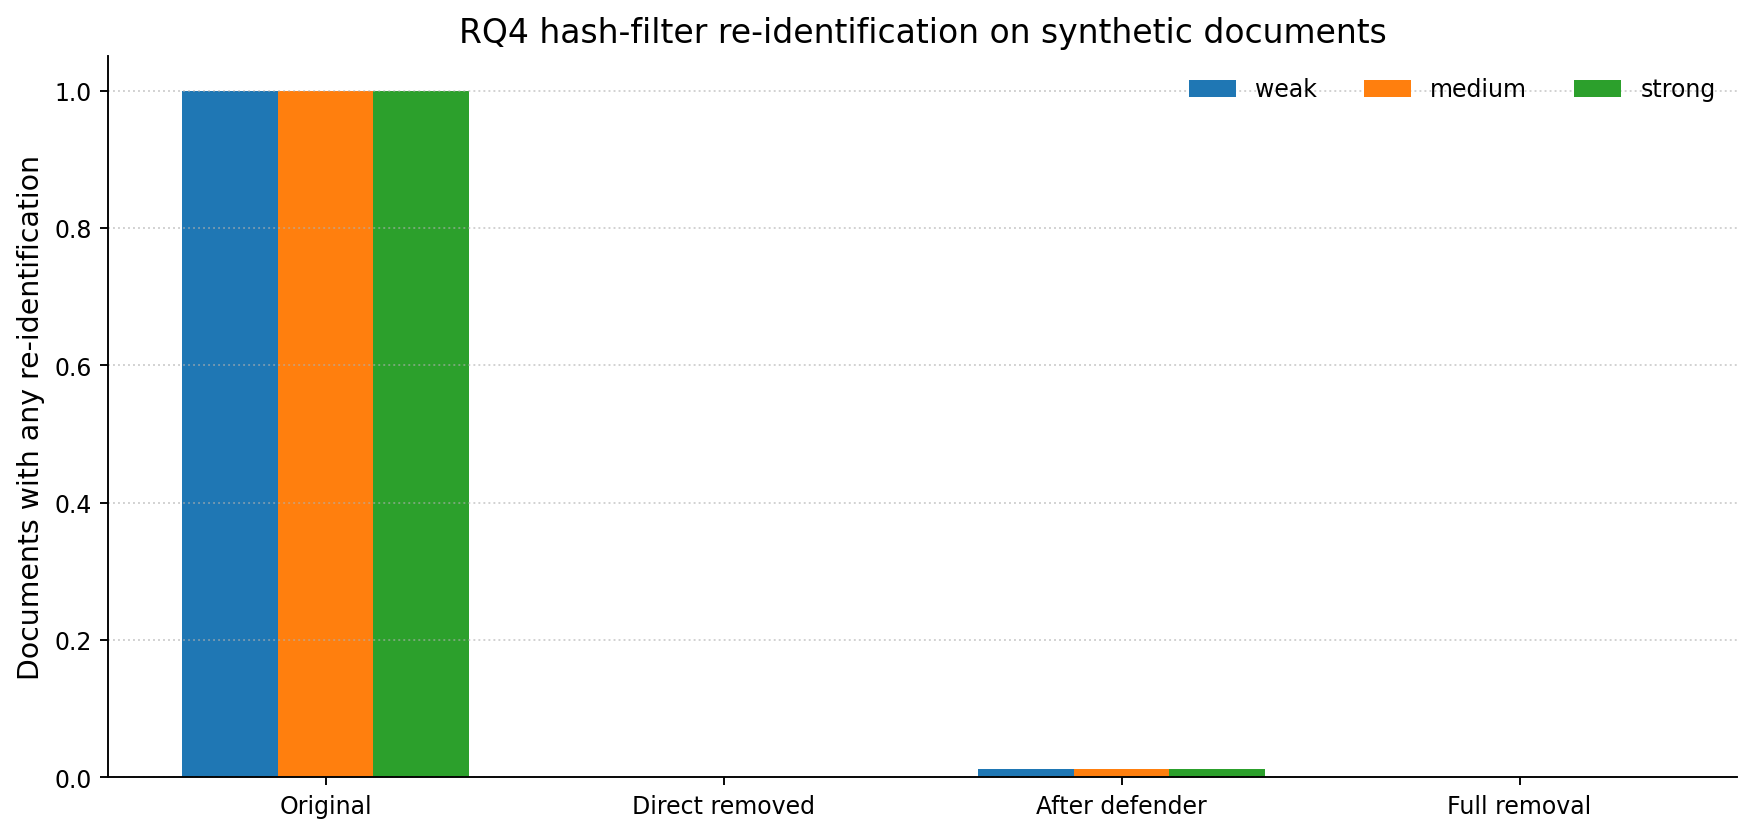

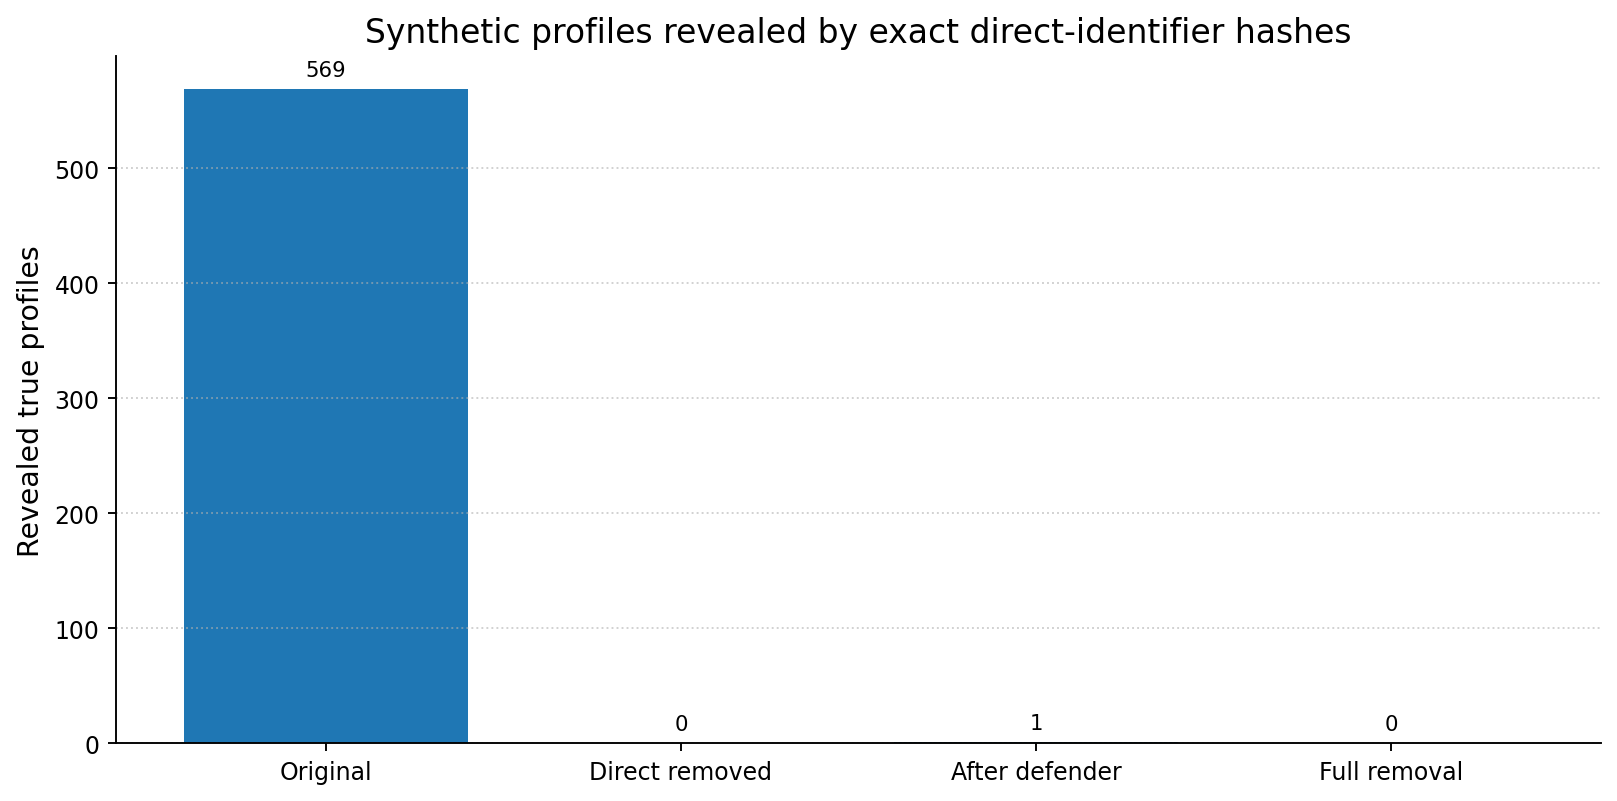

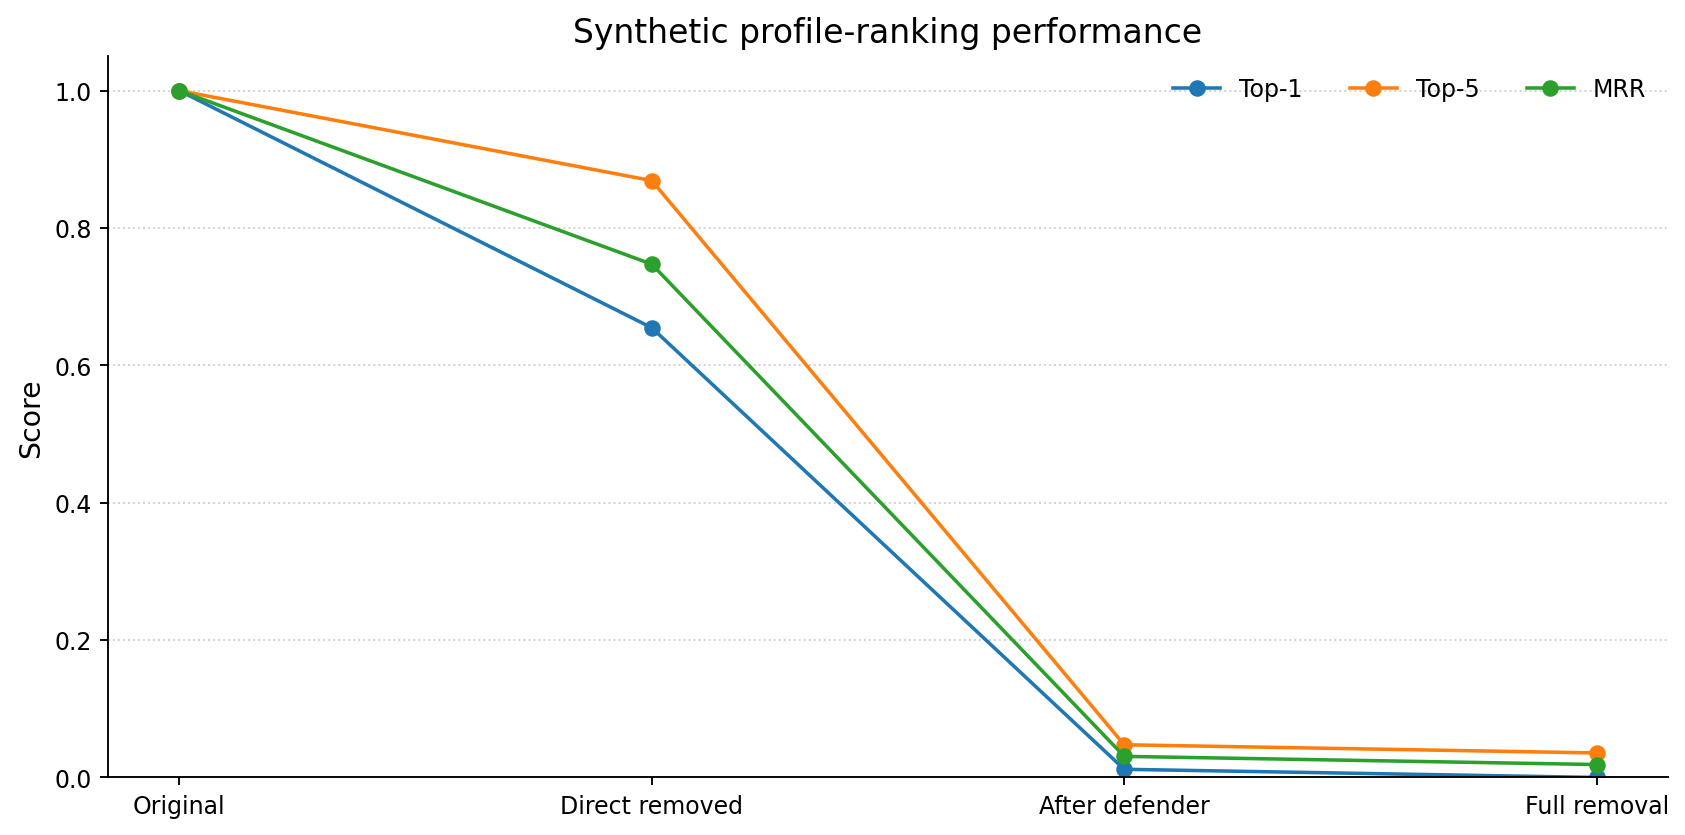

In [4]:
def plot_hash(summary, source, name):
    x = np.arange(len(phases))
    w = 0.24
    fig, ax = plt.subplots(figsize=(10.2, 4.8), constrained_layout=True)
    sub = summary[summary["source"].eq(source)]
    for i, level in enumerate(knowledge_levels):
        y = sub[sub["knowledge_level"].eq(level)].set_index("phase").loc[phases, "reidentification_rate"]
        ax.bar(x + (i - 1) * w, y, width=w, label=level)
    ax.set_title(f"RQ4 hash-filter re-identification on {source.lower()} documents")
    ax.set_ylabel("Documents with any re-identification")
    ax.set_ylim(0, 1.05)
    ax.set_xticks(x)
    ax.set_xticklabels([phase_name[p] for p in phases])
    ax.grid(axis="y", linestyle=":", alpha=0.6)
    ax.legend(frameon=False, ncol=3)
    savefig(name)

plot_hash(hs_syn, "Synthetic", "rq4_synthetic_hash_reidentification")

strong = hs_syn[hs_syn["knowledge_level"].eq("strong")].set_index("phase").loc[phases]
fig, ax = plt.subplots(figsize=(9.4, 4.6), constrained_layout=True)
ax.bar([phase_name[p] for p in phases], strong["direct_hash_profiles"])
ax.set_title("Synthetic profiles revealed by exact direct-identifier hashes")
ax.set_ylabel("Revealed true profiles")
ax.grid(axis="y", linestyle=":", alpha=0.6)
for i, v in enumerate(strong["direct_hash_profiles"]):
    ax.text(i, v + max(strong["direct_hash_profiles"].max(), 1) * 0.02, str(int(v)), ha="center", fontsize=9)
savefig("rq4_synthetic_direct_hash_profiles")

rp = rs_syn.set_index("phase").loc[phases]
fig, ax = plt.subplots(figsize=(9.8, 4.8), constrained_layout=True)
for col, label in [("top1", "Top-1"), ("top5", "Top-5"), ("mrr", "MRR")]:
    ax.plot([phase_name[p] for p in phases], rp[col], marker="o", label=label)
ax.set_title("Synthetic profile-ranking performance")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend(frameon=False, ncol=3)
savefig("rq4_synthetic_ranking")

## 4. Real RQ3 documents

This part uses the manually reviewed RQ3 UI states and the real profile CSV created from the project groups. The original phase uses all reviewed identifiers. The after-defender phase uses only identifiers that required manual addition, which means they were missed before manual correction.

In [5]:
kb_candidates = [
    Path("rq4_manual_groups_knowledge_base.csv"),
    work / "rq4_manual_groups_knowledge_base.csv",
    root / "rq4_manual_groups_knowledge_base.csv",
    root / "notebooks" / "workspace" / "real_docs_kb.csv",
    root / "real_docs_kb.csv",
]
real_kb_path = next((p for p in kb_candidates if p.exists()), None)
assert real_kb_path is not None, "Put rq4_manual_groups_knowledge_base.csv in the notebook folder or notebooks/workspace."

real_atk = Attacker(cfg)
real_kb = real_atk.load_knowledge_base(real_kb_path)

bases = [
    root / "UI" / "rq3_labeling_workspace" / sid,
    root / "UI" / "rq3_labeling_workspace_BACKUP" / sid,
]
folders = []
for b in bases:
    folders += [b / "states", b / "export_build" / "saved_review_state" / "doc_states"]

active = []
for b in bases:
    f = b / "session.json"
    if f.exists() and not active:
        active = [d["doc_id"] for d in json.loads(f.read_text(encoding="utf-8")).get("documents", [])]

seen = {}
for order, folder in enumerate(folders):
    if not folder.exists():
        continue
    for p in sorted(folder.glob("*.json")):
        s = json.loads(p.read_text(encoding="utf-8"))
        did = str(s.get("doc_id", p.stem))
        if did not in seen:
            seen[did] = (order, s)

states = [seen[d][1] for d in active if d in seen] if active else [v[1] for v in seen.values()]
assert states, "No RQ3 state files found. Check sid and the UI workspace folder."

name_labs = {"FULL_NAME", "FIRST_NAME", "LAST_NAME", "Name"}
rows = []
for s in states:
    for e in s.get("entities", []):
        st = str(e.get("status", "accepted"))
        if st not in {"accepted", "manual"}:
            continue
        lab = str(e.get("label", "Other") or "Other")
        if lab == "Name":
            lab = "FULL_NAME"
        src = str(e.get("source", ""))
        manual = bool(e.get("manual")) or st == "manual" or src in {"manual", "manual_review"}
        rows.append({
            "doc_id": s.get("doc_id", ""),
            "template_id": s.get("relative_path", ""),
            "label": canon(lab),
            "surface": str(e.get("surface", "") or ""),
            "region": str(e.get("region", "") or ""),
            "path": str(e.get("path", "") or ""),
            "start": int(e.get("start", -1) or -1),
            "end": int(e.get("end", -1) or -1),
            "manual": manual,
            "auto": not manual,
        })

gold_real = pd.DataFrame(rows)
gold_real = gold_real[gold_real["surface"].str.strip().ne("")].copy()
gold_real["k"] = gold_real["surface"].map(key)
gold_real = gold_real.drop_duplicates(["doc_id", "label", "k", "path", "start", "end"]).reset_index(drop=True)

records_real = [
    SimpleNamespace(doc_id=str(s.get("doc_id", "")), template_id=str(s.get("relative_path", "")))
    for s in states
]

def records_from(df):
    return [ent(r) for _, r in df.iterrows()]

before_real = {d: records_from(g) for d, g in gold_real.groupby("doc_id")}
after_real = {d: records_from(g[g["manual"]]) for d, g in gold_real.groupby("doc_id")}
for rec in records_real:
    before_real.setdefault(rec.doc_id, [])
    after_real.setdefault(rec.doc_id, [])

maps_real = {
    "original": before_real,
    "direct_removed": {d: [e for e in es if canon(e["label"]) not in dlabs] for d, es in before_real.items()},
    "after_defender": after_real,
    "full_removal": {d: [] for d in before_real},
}

profile_sets = {
    r.record: {
        "FULL_NAME": real_atk.profile_values(r, "FULL_NAME"),
        "FIRST_NAME": real_atk.profile_values(r, "FIRST_NAME"),
        "LAST_NAME": real_atk.profile_values(r, "LAST_NAME"),
        "Student number": real_atk.profile_values(r, "Student number"),
        "Institutional email": real_atk.profile_values(r, "Institutional email"),
        "Course code": real_atk.profile_values(r, "Course code"),
        "Group label": real_atk.profile_values(r, "Group label"),
        "Programme": real_atk.profile_values(r, "Programme"),
        "Role": real_atk.profile_values(r, "Role"),
    }
    for r in real_kb
}

def set_for(ents, lab):
    return {_norm(e["surface"]) for e in ents if canon(e["label"]) == lab and _norm(e["surface"])}

def real_truth(ents):
    ids = set()
    for e in ents:
        if canon(e["label"]) in {"FULL_NAME", "Name", "Student number", "Institutional email"}:
            ids |= set(real_atk.direct_hash_matches(e, real_kb))
    firsts = set_for(ents, "FIRST_NAME")
    lasts = set_for(ents, "LAST_NAME")
    groups = set_for(ents, "Group label")
    courses = set_for(ents, "Course code")
    for rec, pv in profile_sets.items():
        if firsts and lasts and firsts.intersection(pv["FIRST_NAME"]) and lasts.intersection(pv["LAST_NAME"]):
            ids.add(rec)
        if groups and groups.intersection(pv["Group label"]):
            ids.add(rec)
    if not ids and courses:
        for rec, pv in profile_sets.items():
            if courses.intersection(pv["Course code"]):
                ids.add(rec)
    return sorted(ids)

truth_real = {d: real_truth(es) for d, es in before_real.items()}
rec_real = [r for r in records_real if truth_real.get(r.doc_id)]

h_real, r_real = attack_tables(rec_real, maps_real, real_kb, truth_real, real_atk, "Real RQ3")
hs_real, rs_real = summarise(h_real, r_real)

scope_real = pd.DataFrame([{
    "source": "Real RQ3",
    "documents": len(rec_real),
    "profiles": len(real_kb),
    "original_mentions": sum(len(v) for v in maps_real["original"].values()),
    "after_defender_mentions": sum(len(v) for v in maps_real["after_defender"].values()),
    "knowledge_base": str(real_kb_path),
}])

display(scope_real)
display(hs_real.round(3))
display(rs_real.round(3))

,source,documents,profiles,original_mentions,after_defender_mentions,knowledge_base
0,Real RQ3,61,37,4338,1001,notebooks\workspace\real_docs_kb.csv


,source,phase,knowledge_level,documents,mean_mentions,reidentified_documents,reidentification_rate,mean_revealed_profiles,direct_hash_profiles,direct_hash_hits,quasi_unique_success,median_quasi_pool
0,Real RQ3,after_defender,medium,61,6.738,10,0.164,0.426,26,29,0.0,37.0
1,Real RQ3,after_defender,strong,61,6.738,10,0.164,0.426,26,29,0.0,37.0
2,Real RQ3,after_defender,weak,61,6.738,10,0.164,0.426,26,29,0.0,37.0
3,Real RQ3,direct_removed,medium,61,3.607,0,0.000,0.000,0,0,0.0,37.0
4,Real RQ3,direct_removed,strong,61,3.607,0,0.000,0.000,0,0,0.0,37.0
5,Real RQ3,direct_removed,weak,61,3.607,0,0.000,0.000,0,0,0.0,37.0
6,Real RQ3,full_removal,medium,61,0.000,0,0.000,0.000,0,0,0.0,37.0
7,Real RQ3,full_removal,strong,61,0.000,0,0.000,0.000,0,0,0.0,37.0
8,Real RQ3,full_removal,weak,61,0.000,0,0.000,0.000,0,0,0.0,37.0
9,Real RQ3,original,medium,61,58.984,61,1.000,5.197,317,362,0.0,37.0


,source,phase,documents,mean_signals,median_candidates,top1,top5,mrr,open_correct,open_false_accept
0,Real RQ3,after_defender,61,2.016,37.0,0.131,0.885,0.402,0.049,0.0
1,Real RQ3,direct_removed,61,3.410,37.0,0.033,0.852,0.322,0.000,0.0
2,Real RQ3,full_removal,61,0.000,37.0,0.000,0.836,0.299,0.000,0.0
3,Real RQ3,original,61,9.738,5.0,1.000,1.000,1.000,0.016,0.0


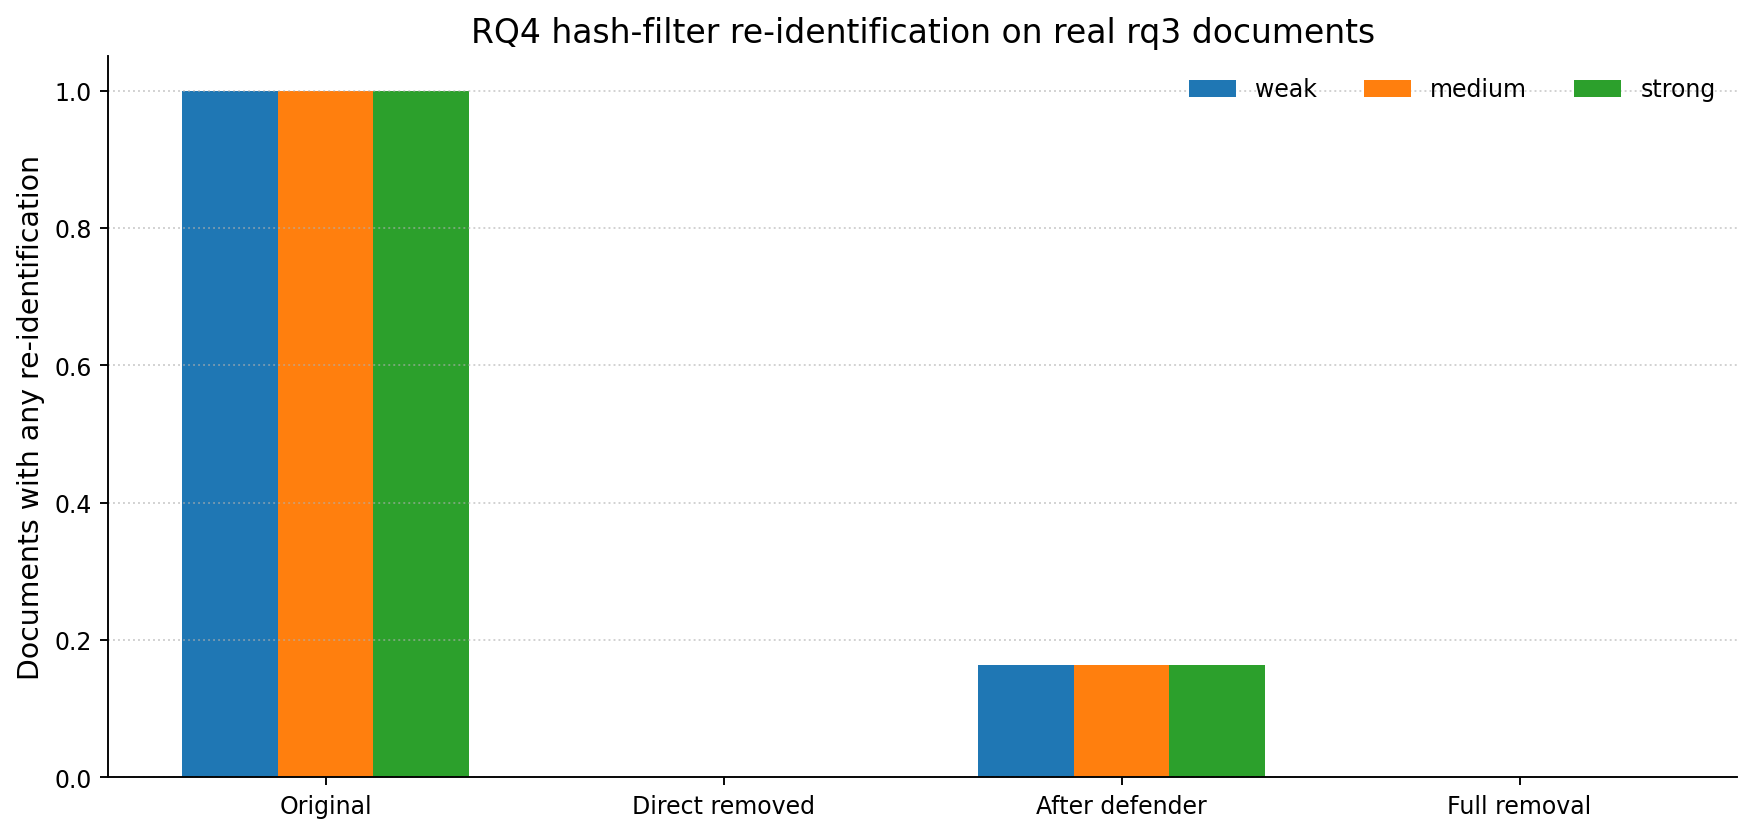

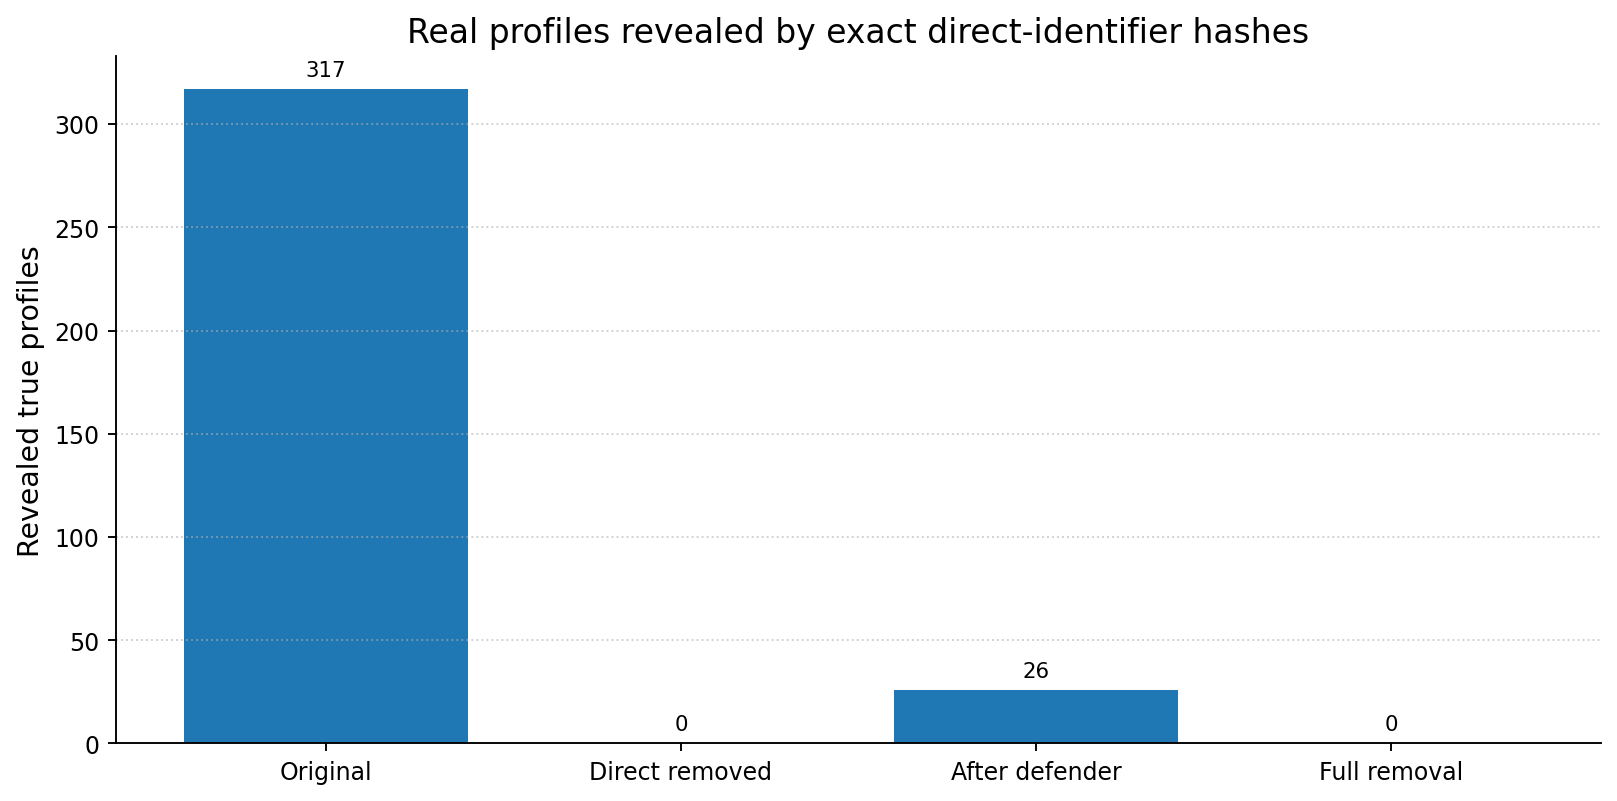

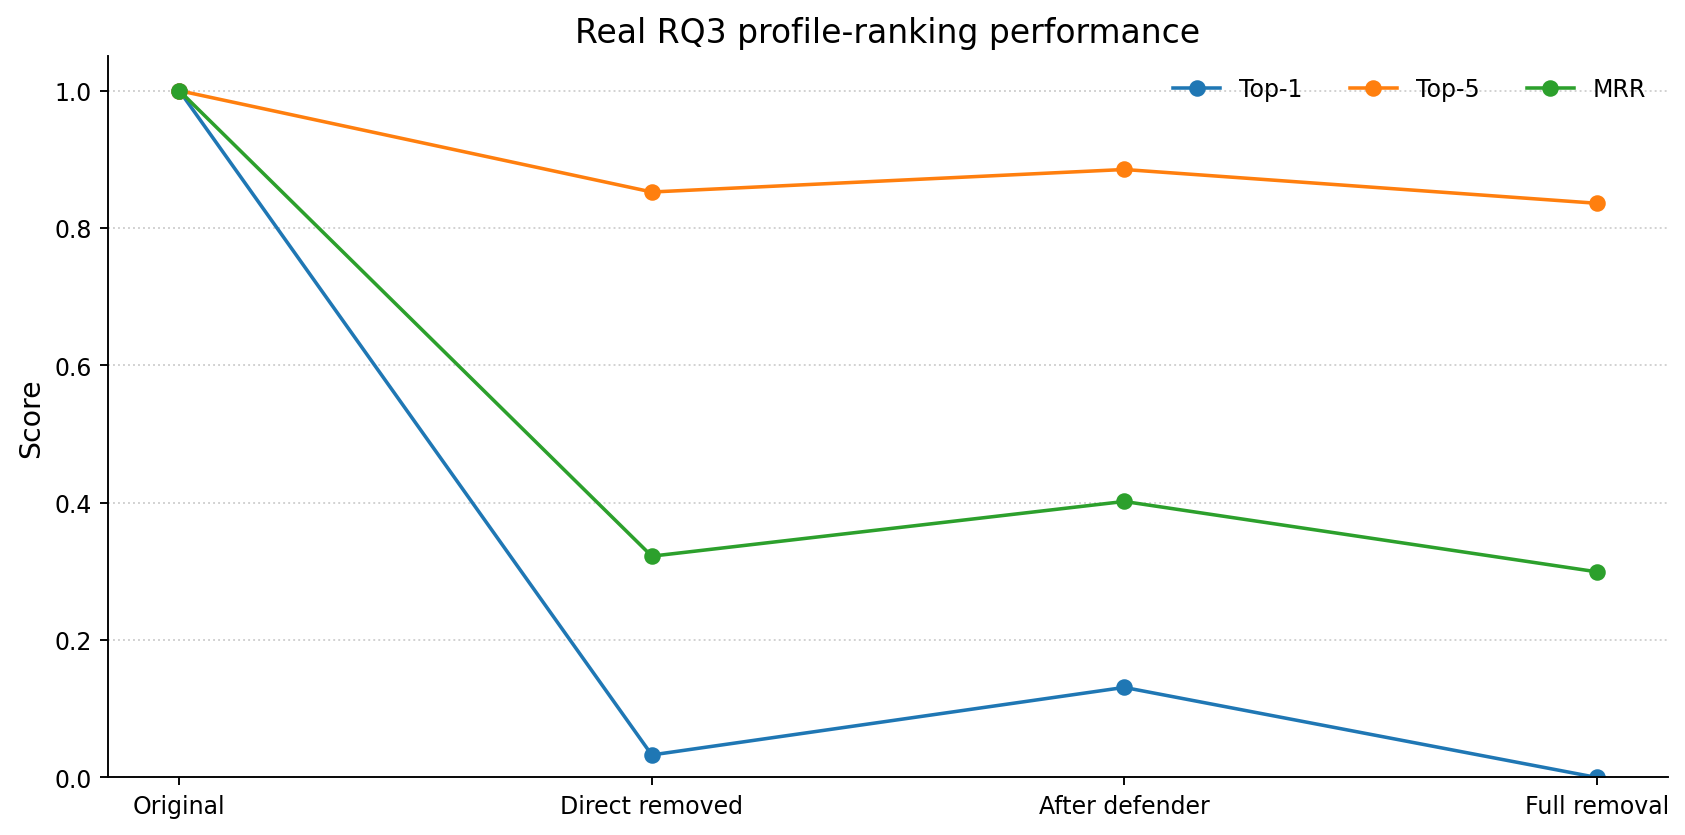

In [6]:
plot_hash(hs_real, "Real RQ3", "rq4_real_hash_reidentification")

strong = hs_real[hs_real["knowledge_level"].eq("strong")].set_index("phase").loc[phases]
fig, ax = plt.subplots(figsize=(9.4, 4.6), constrained_layout=True)
ax.bar([phase_name[p] for p in phases], strong["direct_hash_profiles"])
ax.set_title("Real profiles revealed by exact direct-identifier hashes")
ax.set_ylabel("Revealed true profiles")
ax.grid(axis="y", linestyle=":", alpha=0.6)
for i, v in enumerate(strong["direct_hash_profiles"]):
    ax.text(i, v + max(strong["direct_hash_profiles"].max(), 1) * 0.02, str(int(v)), ha="center", fontsize=9)
savefig("rq4_real_direct_hash_profiles")

rp = rs_real.set_index("phase").loc[phases]
fig, ax = plt.subplots(figsize=(9.8, 4.8), constrained_layout=True)
for col, label in [("top1", "Top-1"), ("top5", "Top-5"), ("mrr", "MRR")]:
    ax.plot([phase_name[p] for p in phases], rp[col], marker="o", label=label)
ax.set_title("Real RQ3 profile-ranking performance")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend(frameon=False, ncol=3)
savefig("rq4_real_ranking")

## 5. Combined report

### RQ4 scope

,source,documents,profiles,original_mentions,after_defender_mentions,knowledge_base
0,Synthetic,84,3500,8768,18,notebooks\workspace\dataset\master_profiles.csv
1,Real RQ3,61,37,4338,1001,notebooks\workspace\real_docs_kb.csv


### Hash-filter attacker

,source,phase,knowledge_level,documents,mean_mentions,reidentified_documents,reidentification_rate,mean_revealed_profiles,direct_hash_profiles,direct_hash_hits,quasi_unique_success,median_quasi_pool
21,Real RQ3,original,medium,61,58.984,61,1.000,5.197,317,362,0.0,37.0
22,Real RQ3,original,strong,61,58.984,61,1.000,5.197,317,362,0.0,37.0
23,Real RQ3,original,weak,61,58.984,61,1.000,5.197,317,362,0.0,37.0
15,Real RQ3,direct_removed,medium,61,3.607,0,0.000,0.000,0,0,0.0,37.0
16,Real RQ3,direct_removed,strong,61,3.607,0,0.000,0.000,0,0,0.0,37.0
17,Real RQ3,direct_removed,weak,61,3.607,0,0.000,0.000,0,0,0.0,37.0
12,Real RQ3,after_defender,medium,61,6.738,10,0.164,0.426,26,29,0.0,37.0
13,Real RQ3,after_defender,strong,61,6.738,10,0.164,0.426,26,29,0.0,37.0
14,Real RQ3,after_defender,weak,61,6.738,10,0.164,0.426,26,29,0.0,37.0
18,Real RQ3,full_removal,medium,61,0.000,0,0.000,0.000,0,0,0.0,37.0


### Ranking attacker

,source,phase,documents,mean_signals,median_candidates,top1,top5,mrr,open_correct,open_false_accept
7,Real RQ3,original,61,9.738,5.0,1.000,1.000,1.000,0.016,0.0
5,Real RQ3,direct_removed,61,3.410,37.0,0.033,0.852,0.322,0.000,0.0
4,Real RQ3,after_defender,61,2.016,37.0,0.131,0.885,0.402,0.049,0.0
6,Real RQ3,full_removal,61,0.000,37.0,0.000,0.836,0.299,0.000,0.0
3,Synthetic,original,84,17.333,76.0,1.000,1.000,1.000,0.214,0.0
1,Synthetic,direct_removed,84,3.976,76.0,0.655,0.869,0.747,0.000,0.0
0,Synthetic,after_defender,84,0.155,3500.0,0.012,0.048,0.031,0.012,0.0
2,Synthetic,full_removal,84,0.000,3500.0,0.000,0.036,0.019,0.000,0.0


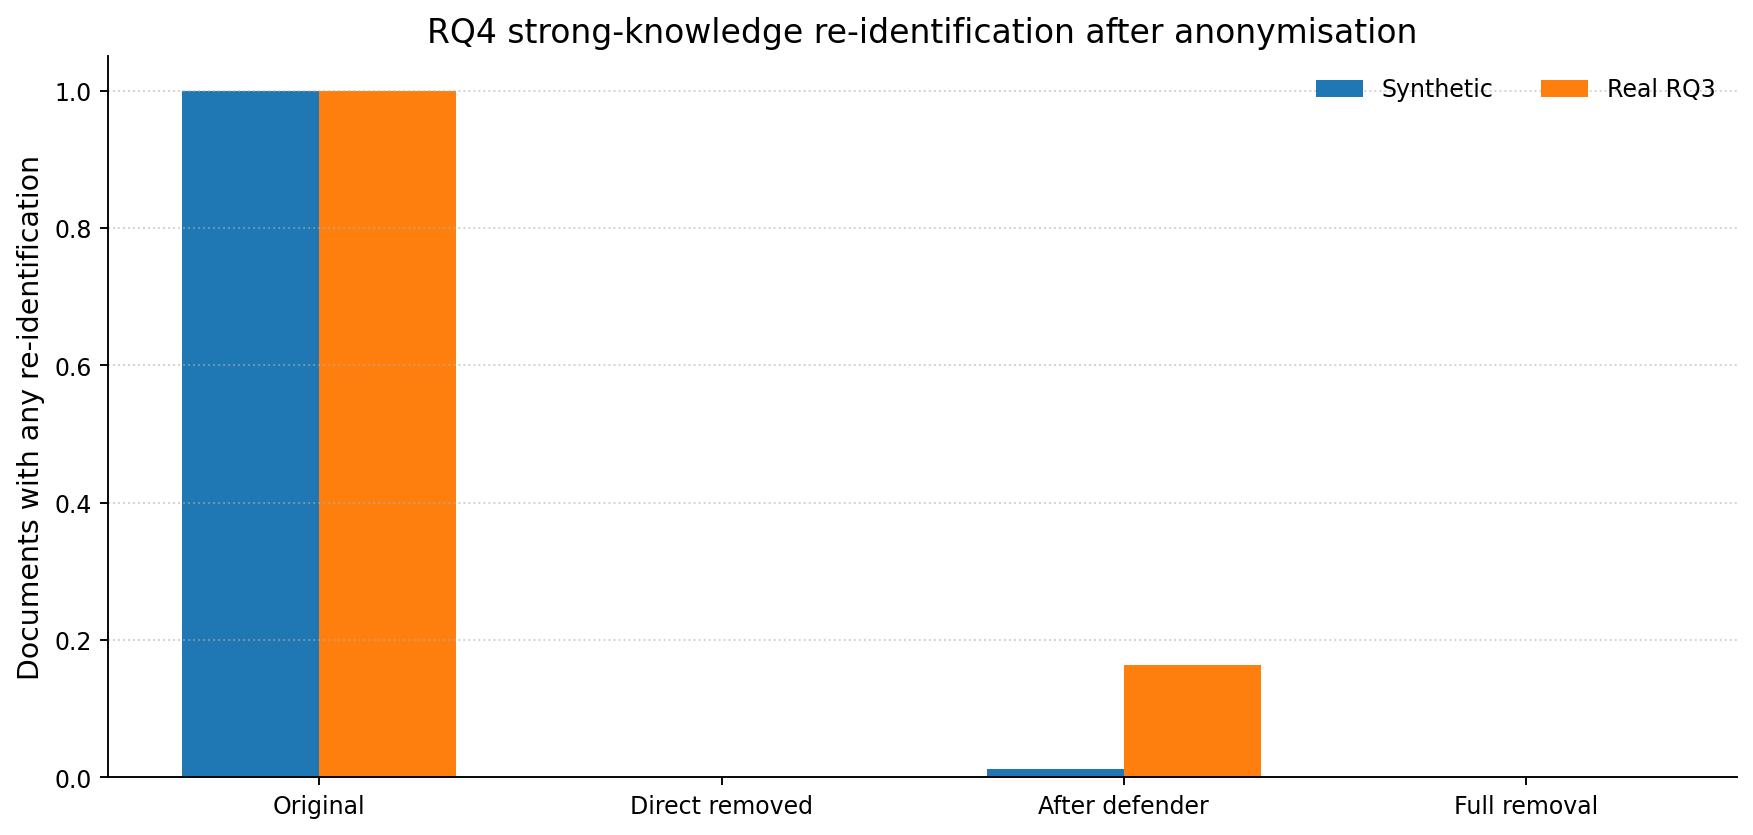

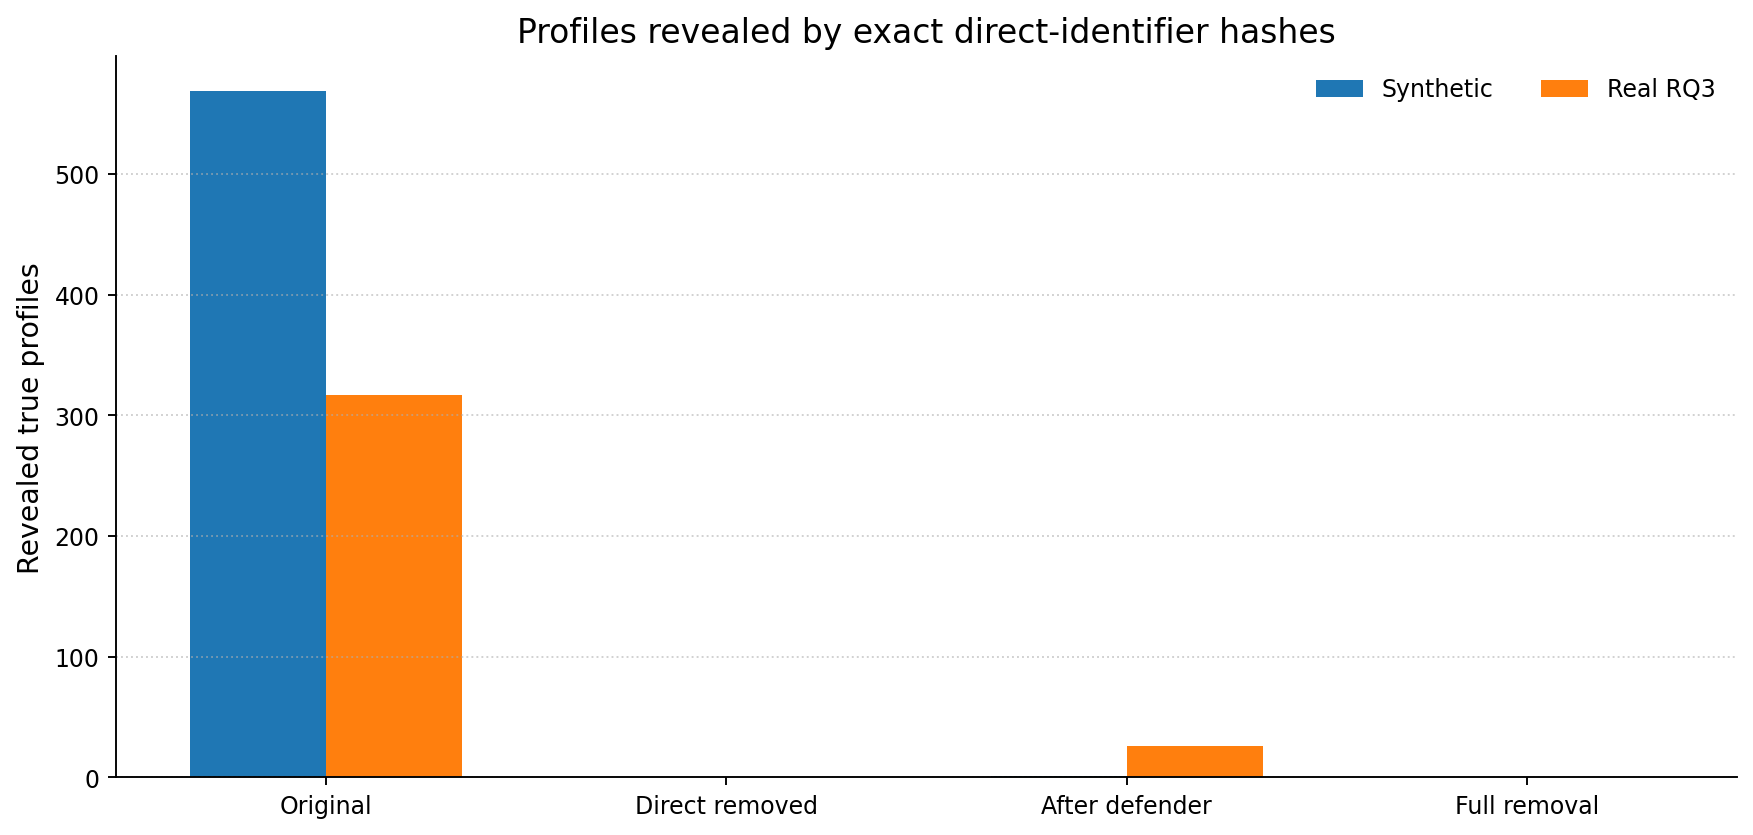

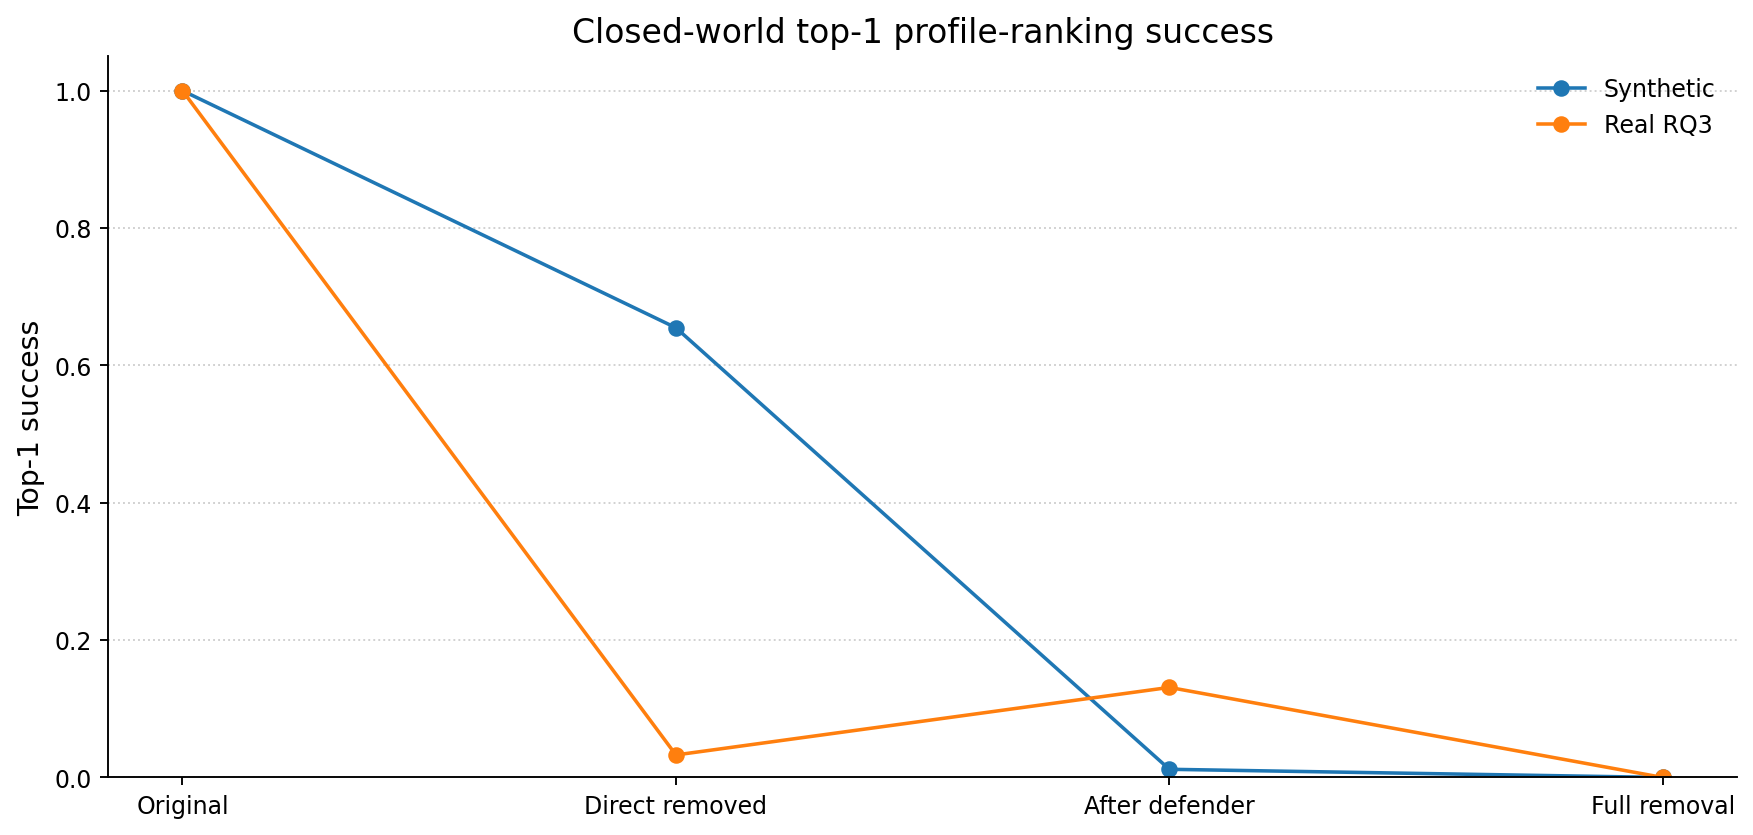

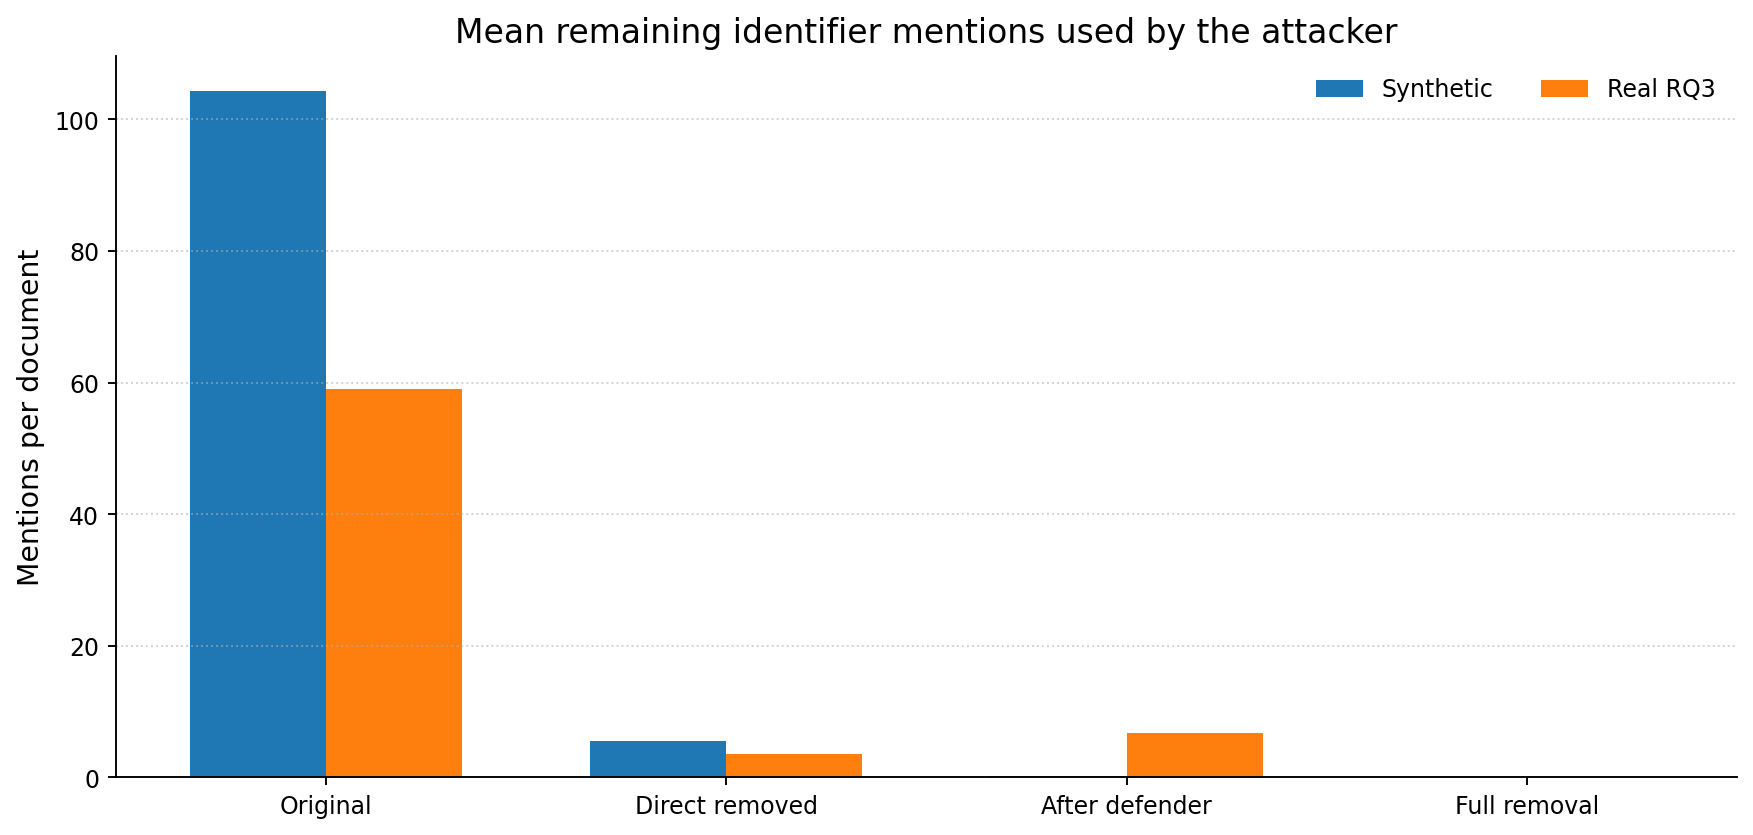

In [7]:
hash_all = pd.concat([hs_syn, hs_real], ignore_index=True)
rank_all = pd.concat([rs_syn, rs_real], ignore_index=True)
scope_all = pd.concat([scope_syn, scope_real], ignore_index=True)

hash_all["phase"] = pd.Categorical(hash_all["phase"], phases, ordered=True)
rank_all["phase"] = pd.Categorical(rank_all["phase"], phases, ordered=True)
hash_all = hash_all.sort_values(["source", "phase", "knowledge_level"])
rank_all = rank_all.sort_values(["source", "phase"])

display(Markdown("### RQ4 scope"))
display(scope_all)
display(Markdown("### Hash-filter attacker"))
display(hash_all.round(3))
display(Markdown("### Ranking attacker"))
display(rank_all.round(3))

# Figure 1. Strong-knowledge hash-filter comparison
x = np.arange(len(phases))
w = 0.34
fig, ax = plt.subplots(figsize=(10.2, 4.8), constrained_layout=True)
for i, source in enumerate(["Synthetic", "Real RQ3"]):
    y = hash_all[(hash_all["source"].eq(source)) & (hash_all["knowledge_level"].eq("strong"))].set_index("phase").loc[phases, "reidentification_rate"]
    ax.bar(x + (i - 0.5) * w, y, width=w, label=source)
ax.set_title("RQ4 strong-knowledge re-identification after anonymisation")
ax.set_ylabel("Documents with any re-identification")
ax.set_ylim(0, 1.05)
ax.set_xticks(x)
ax.set_xticklabels([phase_name[p] for p in phases])
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend(frameon=False, ncol=2)
savefig("rq4_strong_reidentification_comparison")

# Figure 2. Direct hash profile leakage comparison
fig, ax = plt.subplots(figsize=(10.2, 4.8), constrained_layout=True)
for i, source in enumerate(["Synthetic", "Real RQ3"]):
    y = hash_all[(hash_all["source"].eq(source)) & (hash_all["knowledge_level"].eq("strong"))].set_index("phase").loc[phases, "direct_hash_profiles"]
    ax.bar(x + (i - 0.5) * w, y, width=w, label=source)
ax.set_title("Profiles revealed by exact direct-identifier hashes")
ax.set_ylabel("Revealed true profiles")
ax.set_xticks(x)
ax.set_xticklabels([phase_name[p] for p in phases])
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend(frameon=False, ncol=2)
savefig("rq4_direct_hash_profile_comparison")

# Figure 3. Ranking comparison
fig, ax = plt.subplots(figsize=(10.2, 4.8), constrained_layout=True)
for source in ["Synthetic", "Real RQ3"]:
    y = rank_all[rank_all["source"].eq(source)].set_index("phase").loc[phases, "top1"]
    ax.plot([phase_name[p] for p in phases], y, marker="o", label=source)
ax.set_title("Closed-world top-1 profile-ranking success")
ax.set_ylabel("Top-1 success")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend(frameon=False)
savefig("rq4_top1_comparison")

# Figure 4. Remaining identifier mentions
fig, ax = plt.subplots(figsize=(10.2, 4.8), constrained_layout=True)
mentions = hash_all[hash_all["knowledge_level"].eq("strong")].copy()
for i, source in enumerate(["Synthetic", "Real RQ3"]):
    y = mentions[mentions["source"].eq(source)].set_index("phase").loc[phases, "mean_mentions"]
    ax.bar(x + (i - 0.5) * w, y, width=w, label=source)
ax.set_title("Mean remaining identifier mentions used by the attacker")
ax.set_ylabel("Mentions per document")
ax.set_xticks(x)
ax.set_xticklabels([phase_name[p] for p in phases])
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend(frameon=False, ncol=2)
savefig("rq4_remaining_mentions_comparison")

hash_all.to_csv(out / "rq4_hash_filter_summary.csv", index=False)
rank_all.to_csv(out / "rq4_ranking_summary.csv", index=False)
scope_all.to_csv(out / "rq4_scope.csv", index=False)

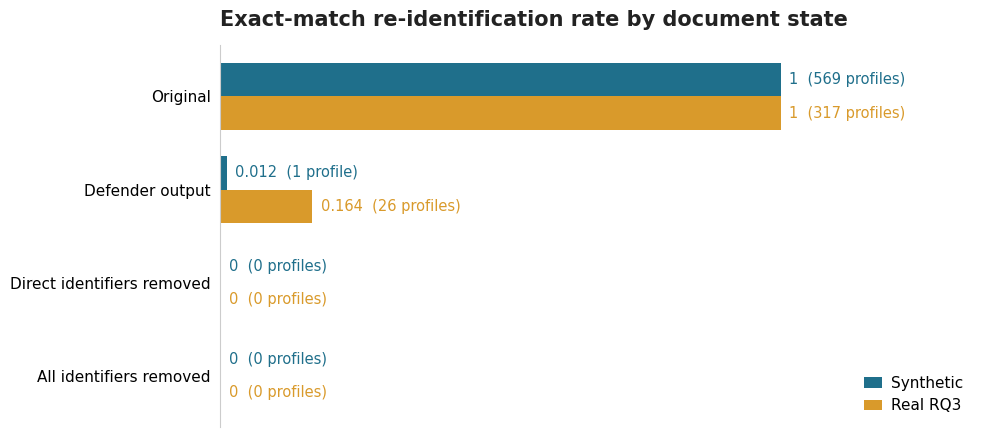

In [3]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
    "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.bottom": False,
})

conds = ["Original", "Defender output",
         "Direct identifiers removed", "All identifiers removed"]
syn_rate  = [1.000, 0.012, 0.000, 0.000]
real_rate = [1.000, 0.164, 0.000, 0.000]
syn_n     = [569, 1, 0, 0]
real_n    = [317, 26, 0, 0]
BLUE, ORANGE = "#1f6f8b", "#d99a2b"

fig, ax = plt.subplots(figsize=(10.0, 4.5))
y = np.arange(len(conds))[::-1]
h = 0.36
sb = ax.barh(y + h/2, syn_rate,  h, color=BLUE,   label="Synthetic")
rb = ax.barh(y - h/2, real_rate, h, color=ORANGE, label="Real RQ3")

def annotate(bars, rates, counts, color):
    for bar, rate, count in zip(bars, rates, counts):
        rate_txt = f"{rate:.3f}".rstrip("0").rstrip(".") if rate > 0 else "0"
        label = f"{rate_txt}  ({count} profile{'s' if count != 1 else ''})"
        ax.text(bar.get_width() + 0.015,
                bar.get_y() + bar.get_height()/2,
                label, va="center", ha="left",
                fontsize=10.5, color=color)

annotate(sb, syn_rate,  syn_n,  BLUE)
annotate(rb, real_rate, real_n, ORANGE)

ax.set_yticks(y); ax.set_yticklabels(conds, fontsize=11)
ax.set_xlim(0, 1.35); ax.set_xticks([]); ax.set_xlabel("")
ax.tick_params(left=False); ax.spines["left"].set_color("#cccccc")
ax.grid(False)
ax.legend(loc="lower right", frameon=False, fontsize=11,
          handlelength=1.2, handletextpad=0.6)
ax.set_title("Exact-match re-identification rate by document state",
             fontsize=15, fontweight="bold", loc="left", pad=14, color="#222222")
fig.tight_layout()
fig.savefig("rq4_exact_match.png", dpi=300, bbox_inches="tight")


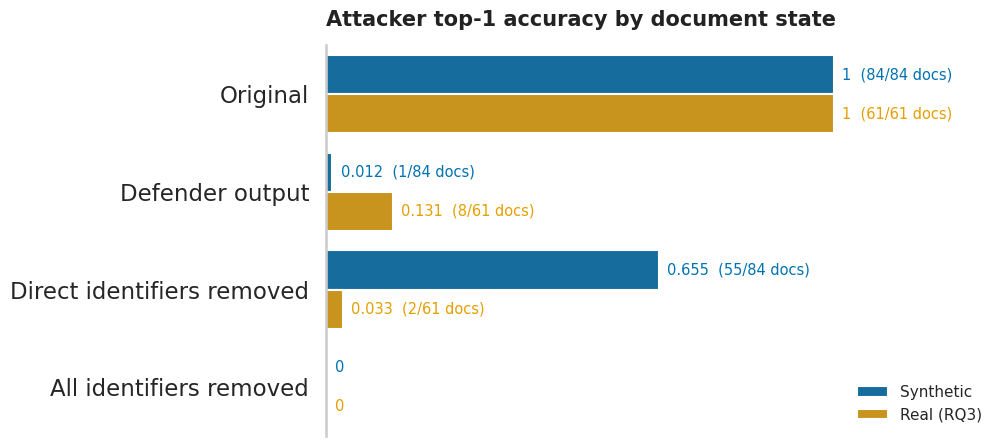

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk", font="DejaVu Sans")

conds = ["Original", "Defender output",
         "Direct identifiers removed", "All identifiers removed"]
syn_top1  = [1.000, 0.012, 0.655, 0.000]
real_top1 = [1.000, 0.131, 0.033, 0.000]
syn_n     = [84, 1, 55, 0]
real_n    = [61, 8, 2, 0]

df = pd.DataFrame({
    "Condition": conds * 2,
    "Dataset":   ["Synthetic"] * 4 + ["Real (RQ3)"] * 4,
    "Top1":      syn_top1 + real_top1,
    "Hits":      syn_n + real_n,
})

palette = {"Synthetic": "#0072B2", "Real (RQ3)": "#E69F00"}
fig, ax = plt.subplots(figsize=(10.4, 4.8))
sns.barplot(data=df, y="Condition", x="Top1", hue="Dataset",
            order=conds, hue_order=["Synthetic", "Real (RQ3)"],
            palette=palette, ax=ax)

for container, dataset, total in zip(ax.containers,
                                     ["Synthetic", "Real (RQ3)"], [84, 61]):
    color = palette[dataset]
    sub = df[df["Dataset"] == dataset].reset_index(drop=True)
    labels = []
    for v, n in zip(sub["Top1"], sub["Hits"]):
        txt = f"{v:.3f}".rstrip("0").rstrip(".") if v > 0 else "0"
        if n > 0:
            txt += f"  ({n}/{total} docs)"
        labels.append(txt)
    ax.bar_label(container, labels=labels, padding=6, fontsize=10.5, color=color)

ax.set_xlim(0, 1.32)
ax.set_xlabel(""); ax.set_ylabel(""); ax.set_xticks([])
ax.tick_params(left=False)
ax.legend(loc="lower right", frameon=False, title=None, fontsize=11)
sns.despine(ax=ax, left=False, bottom=True)
ax.set_title("Attacker top-1 accuracy by document state",
             fontsize=15, fontweight="bold", loc="left", pad=14, color="#222222")
fig.tight_layout()
fig.savefig("rq4_clean.png", dpi=300, bbox_inches="tight")
